# Deck synergy, round 2: deck features, nonland synergy, human drafting as a synergy prior, and pooling sets

`archive/deck_synergy.ipynb` found that on MSH, pair synergy didn't replicate across halves of the data, and that when
it was allowed in, it mostly learned the mana base (basics × same-colour cards). Its takeaways listed the next
steps, all run here on **all 12 sets with game data**:

* give the model the mana base directly: **deck features** from Scryfall data (`cardinfo.deck_features`: land
  count buckets, curve shape, number of colours and splash, how well the lands cast the spells)
* fit the FM on **nonland cards only**, with the deck features alongside, so pairs must be something other than
  colour consistency
* **run the split-half test on every set**
* new: **human drafting as a synergy prior.** The pick model (`picknet` `pool`, notebook `picknet.ipynb`) learns
  how much having card j in your pool raises the odds you take card i: S<sub>ij</sub> = ⟨a<sub>i</sub>, e<sub>j</sub>⟩. Drafters
  take cards that go together, so S is a free estimate of "goes together" from 50-200k drafts per set, made
  without looking at a single game result. Two ways to use it: one extra column (the deck's mean pairwise
  affinity, **one fitted weight**), or the FM's pair vectors as a learned linear map of the pick model's card vectors.
* new topology: **a deck transformer shared across all 12 sets**, reading cards only through their features
  (rules text embedding, Scryfall features, card meta), boosted on each set's own linear model (`scripts/archive/deck_multiset.py`)

Every model is a per-game logistic model with the same context as before (play/draw, mulligans, both ranks,
skill and experience buckets, record before the game), on Premier Draft games, with the same chronological split
(test = games of the last 15% of drafts). Scores are **test log loss minus the linear model's**, game by game on the
same games, with 95% intervals (×1000; negative = better). `scripts/deck_synergy_v2.py`.

Sections:
1. All models on all sets
2. Is the synergy real now? Split-half replication on 12 sets
3. Which deck features matter
4. Human drafting affinity: how much it is worth, and what it pairs
5. A deck network shared across sets
6. Takeaways

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(50); pl.Config.set_tbl_width_chars(200)

R = {p.parts[-3].split(".")[0]: json.loads(p.read_text())
     for p in sorted((ROOT / "results").glob("*.PremierDraft/deck_synergy_v2/results.json"))}
SETS = sorted(R)
MODELS = [m["model"] for m in R["MSH"]["models"]][1:]
SHORT = {"linear + deck features": "deck features", "fm4 nonland + deck features": "FM nonland + DF",
         "fm4 all cards + deck features": "FM all cards + DF", "linear + deck features + draft affinity": "affinity + DF",
         "fm4 nonland + deck features + draft affinity": "FM nonland + affinity + DF",
         "affinity pairs (k=8) + deck features": "affinity-map pairs + DF"}
rows = []
for s in SETS:
    ms = {m["model"]: m for m in R[s]["models"]}
    for m in MODELS:
        if m in ms:
            rows.append({"set": s, "model": SHORT.get(m, m), "vs linear x1000": ms[m]["vs linear"] * 1000,
                         "±95%": ms[m]["vs linear ±95%"] * 1000, "test logloss": ms[m]["test logloss"],
                         "linear test logloss": ms["linear"]["test logloss"]})
long = pl.DataFrame(rows)
print(f"{len(SETS)} sets, {sum(R[s]['games'] for s in SETS):,} games, {sum(R[s]['test games'] for s in SETS):,} test games")

12 sets, 9,156,777 games, 1,326,577 test games


## 1. All models on all sets

Each cell: test log loss minus the linear model's, ×1000, with the 95% interval of the paired difference.

In [2]:
wide = long.with_columns(pl.format("{} ± {}", pl.col("vs linear x1000").round(2), pl.col("±95%").round(2)).alias("cell")) \
    .pivot(on="model", index="set", values="cell")
summary = long.group_by("model").agg(pl.col("vs linear x1000").mean().round(3).alias("mean x1000"),
                                      (pl.col("vs linear x1000") < 0).sum().alias("sets better"),
                                      (pl.col("vs linear x1000") + pl.col("±95%") < 0).sum().alias("sets better, 95% interval below 0"),
                                      pl.len().alias("sets")).sort("mean x1000")
display(wide)
summary

set,deck features,FM nonland + DF,FM all cards + DF,affinity + DF,FM nonland + affinity + DF,affinity-map pairs + DF
str,str,str,str,str,str,str
"""BLB""","""-0.53 ± 0.33""","""-1.39 ± 0.35""","""-1.23 ± 0.37""","""-1.45 ± 0.38""","""-1.8 ± 0.31""","""-1.04 ± 0.41"""
"""DFT""","""-1.0 ± 0.36""","""-1.43 ± 0.41""","""-0.94 ± 0.33""","""-1.25 ± 0.34""","""-1.26 ± 0.34""","""-0.98 ± 0.43"""
"""DSK""","""-0.41 ± 0.31""","""-0.79 ± 0.34""","""-0.73 ± 0.33""","""-1.0 ± 0.35""","""-1.0 ± 0.35""","""-0.86 ± 0.36"""
"""EOE""","""-0.32 ± 0.34""","""-0.65 ± 0.37""","""-0.63 ± 0.38""","""-0.56 ± 0.36""","""-0.68 ± 0.39""","""-0.45 ± 0.34"""
"""FDN""","""-0.69 ± 0.24""","""-0.74 ± 0.27""","""-0.39 ± 0.35""","""-0.89 ± 0.28""","""-0.94 ± 0.28""","""-0.84 ± 0.35"""
"""FIN""","""-0.81 ± 0.25""","""-1.26 ± 0.31""","""-0.82 ± 0.36""","""-1.34 ± 0.34""","""-1.35 ± 0.34""","""-1.17 ± 0.41"""
"""LCI""","""-0.58 ± 0.24""","""-1.14 ± 0.38""","""-0.82 ± 0.31""","""-0.94 ± 0.31""","""-0.98 ± 0.32""","""-1.15 ± 0.4"""
"""MKM""","""-0.63 ± 0.2""","""-1.08 ± 0.24""","""-0.99 ± 0.25""","""-1.13 ± 0.26""","""-1.27 ± 0.27""","""-1.66 ± 0.36"""
"""MSH""","""-0.41 ± 0.31""","""0.11 ± 0.36""","""-0.3 ± 0.35""","""0.55 ± 0.48""","""0.19 ± 0.47""","""-0.31 ± 0.45"""


model,mean x1000,sets better,"sets better, 95% interval below 0",sets
str,f64,u32,u32,u32
"""FM nonland + affinity + DF""",-1.2,11,11,12
"""affinity + DF""",-1.097,11,11,12
"""affinity-map pairs + DF""",-1.059,12,11,12
"""FM nonland + DF""",-1.018,11,11,12
"""FM all cards + DF""",-0.867,12,11,12
"""deck features""",-0.696,12,11,12


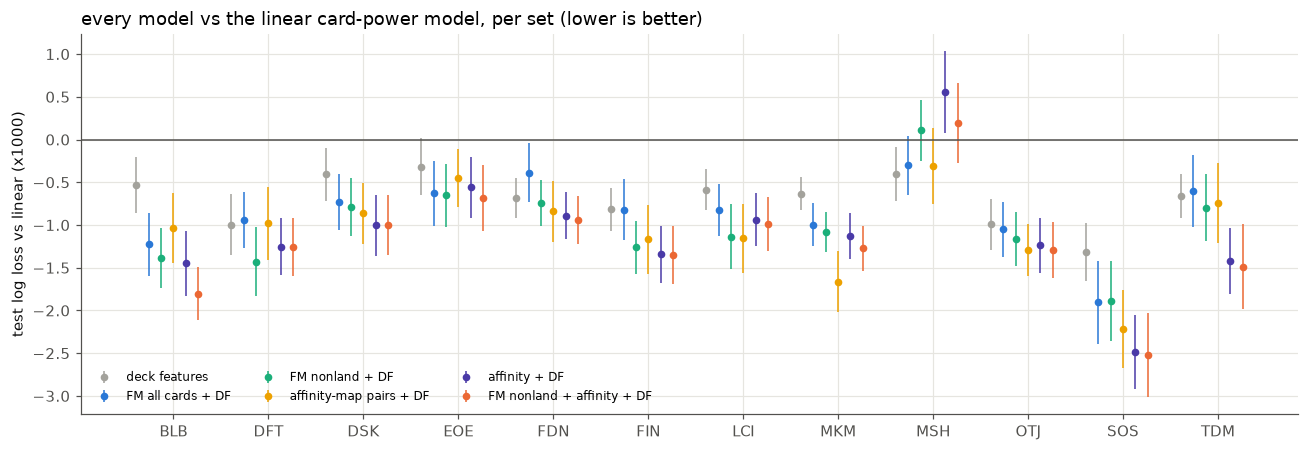

In [3]:
order = summary["model"].to_list()[::-1]
cols = dict(zip(order, [GRAY, BLUE, AQUA, YELLOW, VIOLET, ORANGE][-len(order):]))
fig, ax = plt.subplots(figsize=(12, 4.2))
for j, m in enumerate(order):
    d = long.filter(pl.col("model") == m).sort("set")
    x = np.arange(len(d)) + (j - len(order) / 2) * 0.13
    ax.errorbar(x, d["vs linear x1000"], yerr=d["±95%"], fmt="o", ms=4, color=cols[m], label=m, elinewidth=1)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(np.arange(len(SETS)), SETS)
ax.set_ylabel("test log loss vs linear (x1000)")
ax.set_title("every model vs the linear card-power model, per set (lower is better)", loc="left")
ax.legend(fontsize=8, ncol=3, loc="lower left")
plt.tight_layout()

**Draft level.** The same models as deck ratings: each test draft's most-played deck is scored with the model's
deck terms (card power, pairs, and the deck-level columns: deck features, affinity), calibrated to the event
records on training drafts with rank, as in `deck_synergy.py`, and compared by Spearman with the drafts'
W/(W+L). This is `deckstrength.ipynb`'s headline metric (MSH linear deck model 0.268, LightGBM deck 0.279).
Unlike the game-level scores, these are *not* adjusted for skill at the draft level: a deck-level column that
tracks the drafter's skill (e.g. a coherent build) can gain here without being a property of the deck.

In [4]:
dl = pl.DataFrame([{"set": s, **{SHORT.get(m["model"], m["model"]): m.get("draft spearman") for m in R[s]["models"]}}
                   for s in SETS])
display(dl.with_columns(pl.exclude("set").round(3)))
dl.select(pl.exclude("set").mean().round(4))

set,linear,deck features,FM nonland + DF,FM all cards + DF,affinity + DF,FM nonland + affinity + DF,affinity-map pairs + DF
str,f64,f64,f64,f64,f64,f64,f64
"""BLB""",0.23,0.25,0.261,0.256,0.268,0.268,0.259
"""DFT""",0.201,0.232,0.241,0.228,0.234,0.235,0.245
"""DSK""",0.235,0.255,0.263,0.261,0.268,0.268,0.266
"""EOE""",0.207,0.229,0.236,0.236,0.238,0.238,0.238
"""FDN""",0.257,0.268,0.268,0.261,0.273,0.272,0.272
"""FIN""",0.241,0.258,0.269,0.262,0.271,0.27,0.271
"""LCI""",0.259,0.273,0.283,0.281,0.283,0.284,0.276
"""MKM""",0.221,0.238,0.247,0.246,0.248,0.25,0.25
"""MSH""",0.248,0.261,0.26,0.262,0.276,0.265,0.266


linear,deck features,FM nonland + DF,FM all cards + DF,affinity + DF,FM nonland + affinity + DF,affinity-map pairs + DF
f64,f64,f64,f64,f64,f64,f64
0.2298,0.2495,0.2563,0.2524,0.2618,0.2602,0.2597


## 2. Is the synergy real now? Split-half replication on 12 sets

The training drafts are split in two at random, the nonland FM (with deck features) is refitted on each half,
and the two halves' pair values ⟨v<sub>i</sub>, v<sub>j</sub>⟩ are correlated over pairs that share at least 2,000 training
games. Card power gets the same test as a yardstick. On the old FM (all cards, no deck features), MSH's pairs
replicated at r = 0.09.

set,pairs,power r,pair r,top50 overlap,pair vs draft affinity r
str,i64,f64,f64,i64,f64
"""BLB""",12614,0.894,0.31,9,0.186
"""DFT""",12703,0.924,0.308,9,0.176
"""DSK""",14083,0.92,0.295,12,0.17
"""EOE""",9589,0.829,0.104,4,0.094
"""FDN""",11157,0.888,0.206,6,0.093
"""FIN""",11469,0.865,0.236,5,0.14
"""LCI""",11352,0.922,0.237,4,0.134
"""MKM""",12712,0.897,0.254,11,0.161
"""MSH""",6251,0.85,-0.009,0,0.034


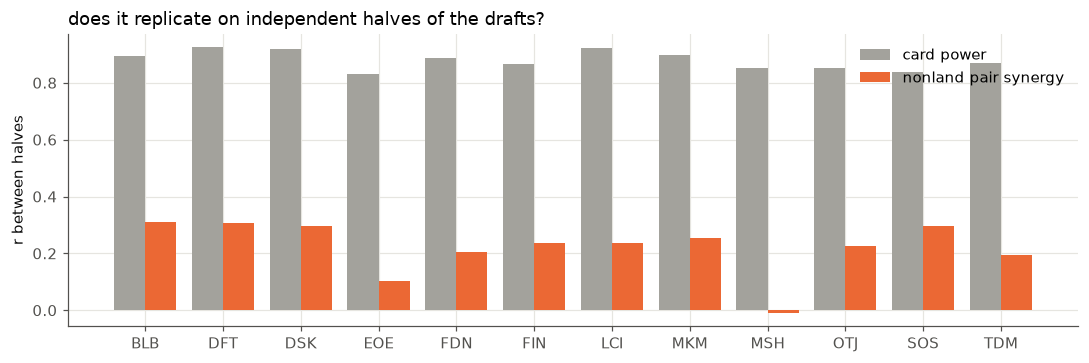

In [5]:
sh = pl.DataFrame([{"set": s, **{k: v for k, v in R[s]["split_half"].items()}} for s in SETS if R[s].get("split_half")])
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(sh))
ax.bar(x - 0.2, sh["power r"], 0.4, color=GRAY, label="card power")
ax.bar(x + 0.2, sh["pair r"], 0.4, color=ORANGE, label="nonland pair synergy")
ax.set_xticks(x, sh["set"]); ax.set_ylabel("r between halves"); ax.legend()
ax.set_title("does it replicate on independent halves of the drafts?", loc="left")
plt.tight_layout()
sh.select("set", "pairs", "power r", "pair r", "top50 overlap", "pair vs draft affinity r").with_columns(
    pl.col("power r", "pair r", "pair vs draft affinity r").round(3))

## 3. Which deck features matter

The weights of `linear + deck features`, in log-odds per standard deviation of the feature (training games), on
every set. The card counts are in the same model, so these are effects *beyond* the cards' own power: e.g. a deck
with 17 lands is the baseline for the land-count buckets.

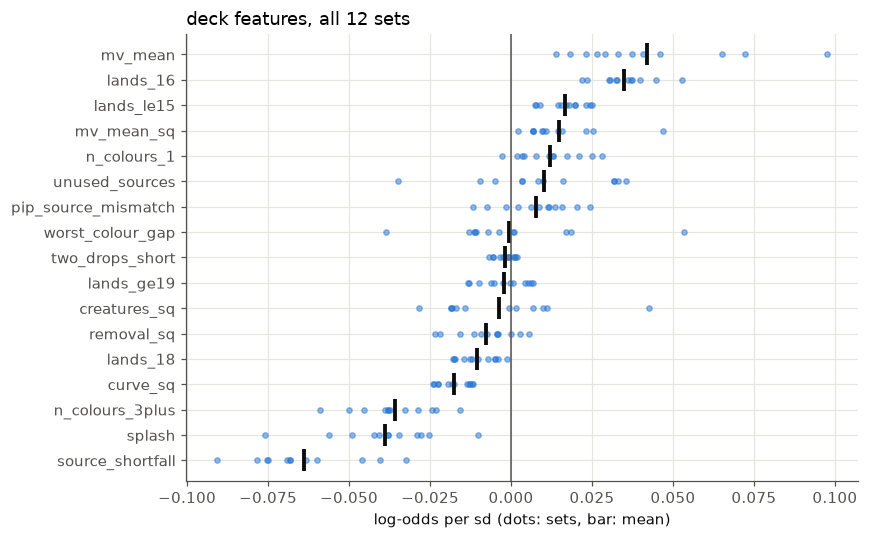

In [6]:
W = pl.DataFrame([{"set": s, **next(m for m in R[s]["models"] if m["model"] == "linear + deck features")["deck feature weights (per sd)"]}
                  for s in SETS])
feats = [c for c in W.columns if c != "set"]
M = W.select(feats).to_numpy()
order = np.argsort(M.mean(0))
fig, ax = plt.subplots(figsize=(8, 5))
for i, j in enumerate(order):
    ax.scatter(M[:, j], np.full(len(M), i), s=12, color=BLUE, alpha=0.5)
    ax.plot([M[:, j].mean()], [i], "|", color=INK, ms=14, mew=2.5)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(np.arange(len(feats)), [feats[j] for j in order])
ax.set_xlabel("log-odds per sd (dots: sets, bar: mean)")
ax.set_title("deck features, all 12 sets", loc="left")
plt.tight_layout()

## 4. Human drafting affinity

**How much is it worth?** `linear + deck features + draft affinity` adds a single column to the deck-features
model, the deck's mean pairwise S<sub>ij</sub> over nonland cards, standardised. Its one weight, per set:

In [7]:
aw = pl.DataFrame([{"set": s,
                    "affinity weight (log-odds per sd)": next(m for m in R[s]["models"] if "affinity weight (log-odds per sd)" in m)["affinity weight (log-odds per sd)"],
                    "gain over deck features x1000": (next(m for m in R[s]["models"] if m["model"] == "linear + deck features + draft affinity")["test logloss"]
                                                    - next(m for m in R[s]["models"] if m["model"] == "linear + deck features")["test logloss"]) * 1000}
                   for s in SETS])
aw.with_columns(pl.exclude("set").round(3))

set,affinity weight (log-odds per sd),gain over deck features x1000
str,f64,f64
"""BLB""",0.159,-0.919
"""DFT""",0.157,-0.257
"""DSK""",0.158,-0.597
"""EOE""",0.097,-0.242
"""FDN""",0.123,-0.203
"""FIN""",0.173,-0.531
"""LCI""",0.154,-0.351
"""MKM""",0.15,-0.498
"""MSH""",0.123,0.959


**What does it pair?** The highest-affinity nonland pairs in the set where affinity helped most, among pairs
that share at least 2,000 training decks, with the number of training decks that contain both, and the lowest.

In [8]:
import torch
from deck_synergy_v2 import pick_affinity
from openlane.cardinfo import card_info
from openlane.deckstrength import aligned, game_split, load_drafts
from openlane.games import game_path

best = aw.sort("gain over deck features x1000")["set"][0]
d = load_drafts(best, "PremierDraft")
S, _ = pick_affinity(best, d.names)
g = pl.read_parquet(game_path(best, "PremierDraft"))
sp = game_split(d, g["draft_id"])
X = aligned(g.filter(pl.Series(sp == 0)), "deck_", d.names).astype(np.float32)
nl = ~card_info(d.names, best)["is_land"].to_numpy()
P = (X[:, nl] > 0).astype(np.float32)
co = P.T @ P
names = np.array(d.names)[nl]
Sn = S[np.ix_(nl, nl)]
iu = np.triu_indices(len(names), 1)
ok = co[iu] >= 2000
top = np.argsort(-Sn[iu][ok])[:15]
bot = np.argsort(Sn[iu][ok])[:8]
a, b = iu[0][ok], iu[1][ok]
show = lambda ix: pl.DataFrame({"card a": names[a[ix]], "card b": names[b[ix]], "affinity": Sn[iu][ok][ix].round(2),
                                "decks together": co[iu][ok][ix].astype(int)})
print(best, "- highest human affinity")
display(show(top))
print("lowest")
show(bot)

SOS - highest human affinity


card a,card b,affinity,decks together
str,str,f32,i64
"""Bogwater Lumaret""","""Pest Mascot""",15.92,25152
"""Blech, Loafing Pest""","""Bogwater Lumaret""",15.55,8497
"""Hardened Academic""","""Spirit Mascot""",14.89,12331
"""Blech, Loafing Pest""","""Pest Mascot""",14.8,7808
"""Pest Mascot""","""Teacher's Pest""",14.67,13290
"""Inkling Mascot""","""Scolding Administrator""",14.62,20392
"""Bogwater Lumaret""","""Essenceknit Scholar""",14.43,15249
"""Conciliator's Duelist""","""Inkling Mascot""",14.23,9965
"""Essenceknit Scholar""","""Teacher's Pest""",14.16,8350


lowest


card a,card b,affinity,decks together
str,str,f32,i64
"""Snarl Song""","""Spellbook Seeker""",-4.43,2285
"""Deluge Virtuoso""","""Snarl Song""",-4.22,3406
"""Encouraging Aviator""","""Potioner's Trove""",-4.14,2686
"""Sundering Archaic""","""Tackle Artist""",-3.92,2296
"""Ajani's Response""","""Noxious Newt""",-3.86,2027
"""Embrace the Paradox""","""Expressive Firedancer""",-3.61,2017
"""Owlin Historian""","""Potioner's Trove""",-3.61,2630
"""Heated Argument""","""Wander Off""",-3.58,2021


In SOS, the set where affinity is worth most (−1.17 ×1000 on top of deck features), the highest-affinity pairs
are one archetype's package: the Pest cards (Pest Mascot, Bogwater Lumaret, Blech, Teacher's Pest, Essenceknit
Scholar) and the Mascot/Academic pairs. These are the cards drafters take *because* they already have the other
one. The lowest-affinity pairs are cards from different colour pairs that rarely end up in the same pool. MSH is
the one set where the affinity column hurts held-out games (+0.96), even though its weight is positive.

**Is it more than co-occurrence, or colour? And is the draft-level gain just skill?** (`scripts/affinity_checks.py`)
Three single columns of the same form (the deck's mean pairwise score over nonland cards, standardised), each on
top of `linear + deck features`: the pick model's affinity; **deck PMI**, plain co-occurrence of the two cards
in training decks; and **colour overlap**, the cosine of the two cards' colour pips. Game level: test log loss vs
deck features. Draft level: Spearman calibrated with rank only, and with rank + the drafter's skill bucket.

In [9]:
ac = {json.loads(p.read_text())["set"]: json.loads(p.read_text())
      for p in sorted((ROOT / "results").glob("*.PremierDraft/deck_synergy_v2/affinity_checks.json"))}
rows = []
for s, r in ac.items():
    for m in r["models"]:
        rows.append({"set": s, "model": m["model"], "vs DF x1000": m["vs deck features x1000"], "±95%": m["±95% x1000"],
                     "draft rho (rank)": m["draft spearman (rank)"], "draft rho (rank + skill)": m["draft spearman (rank + skill)"]})
acl = pl.DataFrame(rows)
display(acl.group_by("model", maintain_order=True).agg(
    pl.col("vs DF x1000").mean().round(3).alias("game: mean vs DF x1000"),
    (pl.col("vs DF x1000") < 0).sum().alias("sets better"),
    pl.col("draft rho (rank)").mean().round(4), pl.col("draft rho (rank + skill)").mean().round(4)))
w = pl.DataFrame([{"set": s, **next(m for m in r["models"] if m["model"] == "+ all three")["column weights"],
                   "r(pick, PMI)": r["column correlations"]["pick affinity ~ deck PMI"]} for s, r in ac.items()])
w.with_columns(pl.exclude("set").round(3))

model,game: mean vs DF x1000,sets better,draft rho (rank),draft rho (rank + skill)
str,f64,u32,f64,f64
"""deck features""",0.0,0,0.2495,0.3713
"""+ pick affinity""",-0.401,11,0.2618,0.3765
"""+ deck PMI""",-0.262,11,0.2592,0.375
"""+ colour overlap""",-0.038,11,0.2519,0.3722
"""+ all three""",-0.441,11,0.2612,0.3764


set,pick affinity,deck PMI,colour overlap,"r(pick, PMI)"
str,f64,f64,f64,f64
"""BLB""",0.149,0.015,-0.031,0.762
"""DFT""",0.182,0.001,-0.074,0.708
"""DSK""",0.226,-0.041,-0.06,0.811
"""EOE""",0.105,0.038,-0.09,0.699
"""FDN""",0.182,0.002,-0.092,0.752
"""FIN""",0.205,0.005,-0.074,0.813
"""LCI""",0.245,-0.045,-0.086,0.714
"""MKM""",0.179,0.014,-0.074,0.734
"""MSH""",0.099,0.029,-0.024,0.679


Pick affinity beats co-occurrence on 10 of 12 sets (LCI ties, MSH is worse for every column) even though the two
columns correlate at r = 0.7-0.84, and when all three go in together, pick affinity takes all the weight (mean
0.18 per sd; PMI −0.01, colour −0.06). So what the pick model adds is not "these cards end up in the same decks" or
"these cards share a colour": it's which cards drafters *take because of* each other. With the skill bucket in
the draft-level calibration, affinity's draft-level gain shrinks from +0.012 to +0.005 Spearman: about 60% of it
was tracking the drafter, the rest survives. (The skill bucket is computed from the same games, so this is a
conservative check.) On MSH every column, even colour overlap, hurts held-out games, which points to a shift
between MSH's training and test weeks rather than to affinity itself.

## 5. A deck network shared across sets

`scripts/archive/deck_multiset.py`. Stage 1 is each set's `linear + deck features` model, fit on that set alone, as a
fixed offset. Stage 2 is one transformer over the deck's distinct cards, shared by all 12 sets, which can only
see a card through its 465 features (no card ids) plus its copies. It's trained on 200k training games per set
(2.4M) to predict what stage 1 misses. Validation is all sets' validation games; test is every test game.
`shared_nodf` is the same without deck features in stage 1, to see whether the shared network finds them itself.

In [10]:
rows = []
for n in ["shared_df", "shared_nodf"]:
    f = ROOT / "results" / "deck_multiset" / f"{n}.json"
    if f.exists():
        r = json.loads(f.read_text())
        for s, v in r["per_set_test"].items():
            rows.append({"run": n, "set": s, "stage 1": v["stage1 logloss"], "shared": v["shared logloss"],
                         "diff x1000": v["diff"] * 1000, "±95%": v["±95%"] * 1000, "set scale": v["set scale"]})
ms = pl.DataFrame(rows)
display(ms.group_by("run").agg(pl.col("diff x1000").mean().round(3).alias("mean diff x1000"),
                               (pl.col("diff x1000") < 0).sum().alias("sets better"), pl.len().alias("sets")))
ms.with_columns(pl.col("stage 1", "shared").round(5), pl.col("diff x1000", "±95%", "set scale").round(3))

run,mean diff x1000,sets better,sets
str,f64,u32,u32
"""shared_df""",-0.093,9,12
"""shared_nodf""",-0.636,12,12


run,set,stage 1,shared,diff x1000,±95%,set scale
str,str,f64,f64,f64,f64,f64
"""shared_df""","""MSH""",0.65519,0.65524,0.052,0.041,0.764
"""shared_df""","""BLB""",0.65721,0.65711,-0.099,0.09,0.81
"""shared_df""","""DFT""",0.65965,0.65953,-0.123,0.057,0.877
"""shared_df""","""DSK""",0.66228,0.66239,0.106,0.08,0.829
"""shared_df""","""FDN""",0.65835,0.65827,-0.081,0.118,0.859
"""shared_df""","""FIN""",0.65885,0.65873,-0.115,0.076,0.879
"""shared_df""","""LCI""",0.65667,0.65596,-0.712,0.139,0.871
"""shared_df""","""MKM""",0.6613,0.66129,-0.012,0.044,0.806
"""shared_df""","""OTJ""",0.66376,0.66398,0.223,0.095,0.76


## 6. Takeaways

1. **Deck features are a free win on every set.** Land-count buckets, curve shape, number of colours and
   splash, and how well the lands cast the spells improve held-out games on 12/12 sets (−0.70 ×1000 on
   average) and draft-level Spearman from 0.230 to 0.249. The biggest effects are about mana: a shortfall of
   coloured sources for the spells (−0.065 log-odds per sd), splashing (−0.04), 3+ main colours (−0.035);
   16 lands beats 17 (+0.035), and a higher average mana value among the nonland cards helps once each card's
   power is held fixed (+0.04).
2. **With the mana base taken out, pair synergy is real on 11 of 12 sets.** Pairs between nonland cards, with
   the deck features alongside, replicate across independent halves of the drafts at r = 0.10-0.31 (card power:
   0.83-0.92) and improve held-out games on 11/12 sets (−1.02). MSH, the smallest set, is the exception on every
   synergy measure (pair r = −0.01), which is why the first synergy notebook, run on MSH, found nothing.
3. **How humans draft is a synergy prior.** The pick model's affinity, learned from picks alone and never from a
   game result, beats the whole nonland FM as a single extra column (−1.10, one fitted weight per set), and the
   FM's learned pairs agree with it (r = 0.09-0.22 where synergy replicates). Stacking both is best on games
   (−1.20), and affinity is best at the draft level (Spearman 0.262 against 0.271 for the draft-trained LightGBM
   deck model and 0.230 for linear). Caveat: at the draft level a coherent build may also mark a stronger
   drafter. On MSH affinity helps the draft-level score (0.248 → 0.276) but not the skill-adjusted game score.
4. **A deck transformer pooled over 12 sets finds general deck structure, but the deck features already have
   it.** Reading cards only through their features, it gains −0.64 ×1000 over plain linear on 12/12 sets
   (`shared_nodf`), about 90% of what the hand-built deck features give (−0.70). On top of linear + deck
   features it adds only −0.09 (9/12). What is left after that is specific to each set (which cards go together),
   and the set's own drafts (affinity) and games (nonland FM) are where it shows up.
5. **It isn't co-occurrence or colour.** Deck co-occurrence (PMI) as the same single column gains less (−0.26 vs
   −0.40 on top of deck features), colour overlap almost nothing (−0.04), and fitted together pick affinity takes
   all the weight. About 60% of its draft-level gain goes away once the drafter's skill is in the calibration;
   the game-level gain is skill-adjusted already.
6. **Next:** use the affinity as a prior *inside* the FM (shrink pair vectors toward the affinity, not toward
   zero); try affinity from PickNet (context-aware) instead of the bilinear pool model.